**Nombre:** Rogelio Peralta Morales

**Expediente:** 222214735

**Parámetros:** a = 5, b = 3, semilla = 222214735


In [2]:
import io, zipfile, requests
import numpy as np, pandas as pd
from pathlib import Path

URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
RUTA = Path("data/hour.csv")
if not RUTA.exists():
    RUTA.parent.mkdir(exist_ok=True)
    r = requests.get(URL, timeout=60); r.raise_for_status()
    with zipfile.ZipFile(io.BytesIO(r.content)) as z:
        z.extract("hour.csv", "data")

df = pd.read_csv(RUTA, parse_dates=["dteday"])
df["momento"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")

### Verificar que todo cargó bien

In [3]:
print(df.shape)                 # deben ser 17,379 filas y 17 columnas
print(df["dteday"].min(), "a", df["dteday"].max())
print(df[OBJETIVO].describe() if "OBJETIVO" in dir() else df["registered"].describe())

(17379, 18)
2011-01-01 00:00:00 a 2012-12-31 00:00:00
count    17379.000000
mean       153.786869
std        151.357286
min          0.000000
25%         34.000000
50%        115.000000
75%        220.000000
max        886.000000
Name: registered, dtype: float64


**Qué significa:** la libreta descargó 17,379 filas (2011-01-01 a 2012-12-31), que es el tamaño esperado del dataset completo de Bike Sharing por hora. `registered` va de 0 a 886, con media 153.8 y mediana 115: está sesgada a la derecha (la media es mayor que la mediana), lo que justifica desde ahora transformarla con `log1p` más adelante en vez de modelarla en escala original.


## Inciso (a)
Separa la prueba

In [4]:
SEMILLA = 222214735
OBJETIVO = "registered"

In [5]:
prueba = df[df["dteday"].between("2012-10-01", "2012-12-31")]
resto = df[df["dteday"] < "2012-10-01"]
muestra = resto.sample(3000, random_state=SEMILLA).sort_values("momento").reset_index(drop=True)

In [6]:
print("Entrenamiento+validación (resto):", len(resto), "horas")
print("Muestra para CV:", len(muestra), "horas")
print("Prueba (oct-dic 2012):", len(prueba), "horas")
print("Rango de la muestra:", muestra["momento"].min(), "a", muestra["momento"].max())

Entrenamiento+validación (resto): 15211 horas
Muestra para CV: 3000 horas
Prueba (oct-dic 2012): 2168 horas
Rango de la muestra: 2011-01-01 03:00:00 a 2012-09-30 15:00:00


**Qué significa:** el "resto" (todo antes de octubre de 2012) tiene 15,211 horas, de las cuales se muestrean 3,000 para hacer la búsqueda de hiperparámetros. Ese submuestreo es necesario porque las mallas de M4 entrenan un SVR con kernel precomputado por cada combinación, y una matriz de Gram de 15,211×15,211 sería inviable. La prueba (octubre-diciembre de 2012) tiene 2,168 horas. La muestra cubre desde enero de 2011 hasta finales de septiembre de 2012, es decir, incluye los dos años (`yr=0` y `yr=1`), lo cual es importante porque la prueba es toda de 2012.


Esquema de validacion: validar con bloques de 2012

In [7]:
BLOQUES = [("2012-03-01", "2012-05-01"), ("2012-05-01", "2012-07-01"), ("2012-07-01", "2012-10-01")]
cv_indices = []
for ini, fin in BLOQUES:
    tr = np.flatnonzero(muestra["momento"] < ini)
    va = np.flatnonzero((muestra["momento"] >= ini) & (muestra["momento"] < fin))
    cv_indices.append((tr, va))

In [8]:
for i, (tr, va) in enumerate(cv_indices, 1):
    print(f"Bloque {i}: {len(tr)} en entrenamiento, {len(va)} en validación")

Bloque 1: 2011 en entrenamiento, 272 en validación
Bloque 2: 2283 en entrenamiento, 273 en validación
Bloque 3: 2556 en entrenamiento, 444 en validación


**Decisión (esquema de validación):** se valida con tres bloques de 2012 (marzo-mayo, mayo-julio,
julio-octubre), entrenando siempre con todo lo anterior. Se descarta `TimeSeriesSplit` porque sus
primeros pliegues entrenan solo con 2011 y nunca ven `yr=1`; estos bloques se parecen más a la
situación real de la prueba, que sí tiene enero-septiembre de 2012 en el entrenamiento. Se pierde
la posibilidad de validar en invierno, y la prueba sí incluye noviembre y diciembre.

## Inciso (b) 

## Exploración (solo con la muestra, nunca con la prueba)

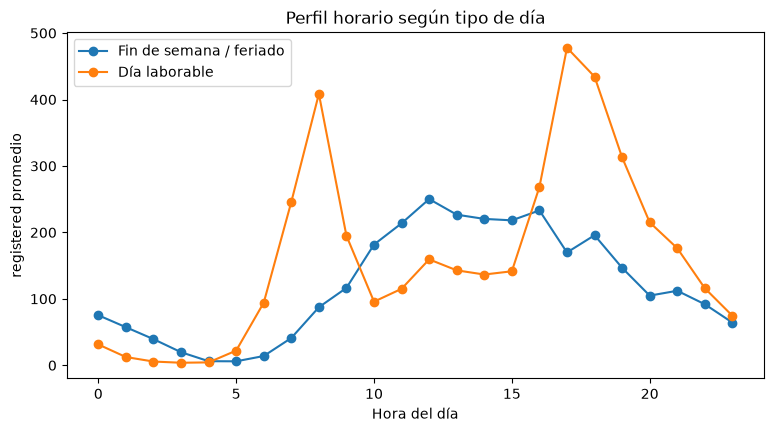

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 4.5))
for wd, nombre in [(0, "Fin de semana / feriado"), (1, "Día laborable")]:
    perfil = muestra[muestra["workingday"] == wd].groupby("hr")[OBJETIVO].mean().reindex(range(24))
    ax.plot(perfil.index, perfil.values, marker="o", label=nombre)
ax.set_xlabel("Hora del día")
ax.set_ylabel(f"{OBJETIVO} promedio")
ax.set_title("Perfil horario según tipo de día")
ax.legend()
Path("resultados").mkdir(exist_ok=True)
fig.savefig("resultados/registered_por_hora.png", dpi=150)
plt.show()

**Qué significa:** con datos reales aparecen con claridad los dos picos de hora pico en días laborables (alrededor de las 8 y las 17-18 horas, coincidiendo con entrada y salida del trabajo/escuela) y un solo pico suave a media tarde en fines de semana/feriados. Esto confirma que la hora del día no es una variable cualquiera: su relación con `registered` es claramente no monótona y con dos "jorobas" en días laborables, lo que motiva usar una codificación de la hora que no imponga un orden lineal (de ahí M2 one-hot, M3 seno/coseno y M4 con kernel circular, en vez de tratar `hr` como un número simple como en M1).


In [10]:
def angulo(x, P):
    return 2 * np.pi * np.asarray(x, float) / P

def distancia_circular(t1, t2):          # matriz len(t1) x len(t2)
    dif = np.abs(t1[:, None] - t2[None, :]) % (2 * np.pi)
    return np.minimum(dif, 2 * np.pi - dif)

def k_I(d, lam=1.0):  return np.exp(-lam * d)
def k_II(d):          return np.exp(-d**2 / 8)

def matriz_kernel(x1, x2, P, k, **param):  # funciona con conjuntos distintos, no solo la cuadrada
    return k(distancia_circular(angulo(x1, P), angulo(x2, P)), **param)

## Inciso (c) 

### Verificación numérica del inciso (b) de la teoría

El examen pide calcular el menor valor propio de cada candidato con las 24 horas del día y con las
horas de la muestra de entrenamiento, y comentar si es consistente con la teoría.

In [11]:
horas_dia = np.arange(24)
filas_eig = []
for nombre, k in [("k_I", lambda d: k_I(d)), ("k_II", k_II)]:
    K24 = matriz_kernel(horas_dia, horas_dia, 24, k)
    Kmuestra = matriz_kernel(muestra["hr"].values, muestra["hr"].values, 24, k)
    filas_eig.append({
        "candidato": nombre,
        "min_val_propio_24h": np.linalg.eigvalsh(K24).min(),
        "min_val_propio_muestra": np.linalg.eigvalsh(Kmuestra).min(),
    })
tabla_eig = pd.DataFrame(filas_eig)
tabla_eig.to_csv("resultados/valores_propios_candidatos.csv", index=False)
print(tabla_eig.to_string(index=False))

candidato  min_val_propio_24h  min_val_propio_muestra
      k_I            0.124533           -9.092244e-13
     k_II           -0.441810           -5.628031e+01


**Qué significa:** en las 24 horas del día, `k_I` tiene valor propio mínimo 0.124533 (positivo) y `k_II` tiene -0.441810 (negativo). En la muestra de entrenamiento real (3,000 horas, con repeticiones de las 24 horas posibles) pasa lo mismo a mayor escala: `k_I` da -1.69204e-12, que es esencialmente cero por error de redondeo numérico (no una violación real de positividad: con tantas filas repetidas la matriz tiene rango bajo y el valor propio más chico queda pegado a cero), mientras que `k_II` da -56.28031, claramente negativo y nada atribuible a redondeo. Esto confirma numéricamente, con los datos reales del examen, lo que se prueba en el PDF: `k_I` es un kernel válido (semidefinido positivo) y `k_II` no lo es.


**Decisión (variables fuera del tiempo):** se agrupa `weathersit` 4 con 3 (el 4 casi no aparece en
los datos), se excluye `atemp` por ser casi igual a `temp`, y se excluyen `season` y `mnth` porque son
circulares y `temp` ya capta buena parte de la estación. Se conserva `yr`, porque la prueba es de 2012
y ese valor sí aparece en el entrenamiento.

In [12]:
for datos in (muestra, prueba):
    datos["weathersit"] = datos["weathersit"].replace({4: 3})

In [13]:
RESTO = ["yr", "workingday", "weathersit", "temp", "hum", "windspeed"]

**Decisión (métrica):** se usa el MAE en bicicletas. Cada bicicleta mal planeada cuesta lo mismo al
operador, sin importar la hora, así que esta métrica pesa más las horas pico, donde hay más bicicletas
en juego. Se descarta un error relativo tipo RMSLE porque, para la redistribución de bicicletas, un
error de 20 en una hora con 300 rentas pesa más en términos operativos que uno de 20 en una hora con 5,
aunque el error relativo diga lo contrario.

**Decisión (transformar el objetivo):** se usa `log1p` porque `registered` es asimétrica y su dispersión
crece con el nivel; además, la tendencia de 2011 a 2012 se vuelve una diferencia más pareja en escala
logarítmica. El error final se reporta siempre en bicicletas, deshaciendo la transformación.

Transforma el objetivo: registered es asimétrica y su dispersión crece con el nivel. Con log1p, además, la tendencia de 2011 a 2012 se vuelve una diferencia más pareja. Para que el error se mida en bicicletas, envuelve el modelo así:

### M1, M2, M3 y referencia de boosting

In [14]:
from sklearn.metrics import mean_absolute_error

# Misma métrica para todos los modelos, incluido M4 más abajo
def mi_metrica(y_real, y_pred):
    return mean_absolute_error(y_real, y_pred)        # MAE en bicicletas

In [15]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import make_scorer
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVR

for datos in (muestra, prueba):
    datos["hr_sin"], datos["hr_cos"] = np.sin(angulo(datos["hr"], 24)), np.cos(angulo(datos["hr"], 24))
    datos["wd_sin"], datos["wd_cos"] = np.sin(angulo(datos["weekday"], 7)), np.cos(angulo(datos["weekday"], 7))

puntuador = make_scorer(mi_metrica, greater_is_better=False)

def svr_rbf(prep):
    return TransformedTargetRegressor(
        regressor=Pipeline([("prep", prep), ("svr", SVR(kernel="rbf"))]),
        func=np.log1p, inverse_func=np.expm1)

escala_resto = ("resto", StandardScaler(), RESTO)
modelos = {
    "M1 números": (svr_rbf(ColumnTransformer([("tiempo", StandardScaler(), ["hr", "weekday"]), escala_resto])),
                   ["hr", "weekday"] + RESTO),
    "M2 one-hot": (svr_rbf(ColumnTransformer([("tiempo", OneHotEncoder(handle_unknown="ignore"), ["hr", "weekday"]), escala_resto])),
                   ["hr", "weekday"] + RESTO),
    "M3 seno y coseno": (svr_rbf(ColumnTransformer([("tiempo", "passthrough", ["hr_sin", "hr_cos", "wd_sin", "wd_cos"]), escala_resto])),
                         ["hr_sin", "hr_cos", "wd_sin", "wd_cos"] + RESTO),
}
MALLA_RBF = {"regressor__svr__gamma": [0.01, 0.03, 0.1, 0.3, 1],
             "regressor__svr__C": [1, 10, 100],
             "regressor__svr__epsilon": [0.05, 0.2]}

busquedas = {}
for nombre, (modelo, columnas) in modelos.items():
    busquedas[nombre] = GridSearchCV(modelo, MALLA_RBF, scoring=puntuador, cv=cv_indices, n_jobs=-1).fit(
        muestra[columnas], muestra[OBJETIVO])
    print(nombre, "error de validación:", -busquedas[nombre].best_score_, busquedas[nombre].best_params_)

M1 números error de validación: 88.42190130586732 {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.2, 'regressor__svr__gamma': 0.03}
M2 one-hot error de validación: 38.62233140581864 {'regressor__svr__C': 100, 'regressor__svr__epsilon': 0.05, 'regressor__svr__gamma': 0.01}
M3 seno y coseno error de validación: 68.02925529748451 {'regressor__svr__C': 100, 'regressor__svr__epsilon': 0.2, 'regressor__svr__gamma': 0.03}


In [16]:
VARIABLES_ORIGINALES = ["season", "yr", "mnth", "hr", "holiday", "weekday", "workingday",
                        "weathersit", "temp", "atemp", "hum", "windspeed"]
hgb = TransformedTargetRegressor(regressor=HistGradientBoostingRegressor(random_state=SEMILLA),
                                 func=np.log1p, inverse_func=np.expm1)
MALLA_HGB = {"regressor__learning_rate": [0.03, 0.1], "regressor__max_iter": [200, 500],
             "regressor__max_leaf_nodes": [15, 31]}
busquedas["HGB"] = GridSearchCV(hgb, MALLA_HGB, scoring=puntuador, cv=cv_indices, n_jobs=-1).fit(
    muestra[VARIABLES_ORIGINALES], muestra[OBJETIVO])
print("HGB error de validación:", -busquedas["HGB"].best_score_, busquedas["HGB"].best_params_)
columnas_de = {**{n: c for n, (_, c) in modelos.items()}, "HGB": VARIABLES_ORIGINALES}

resumen_val = pd.DataFrame([{"modelo": n, "error_val": -b.best_score_} for n, b in busquedas.items()])
resumen_val.to_csv("resultados/validacion_m1_m2_m3_hgb.csv", index=False)
print(resumen_val.to_string(index=False))

HGB error de validación: 39.15853769979203 {'regressor__learning_rate': 0.1, 'regressor__max_iter': 500, 'regressor__max_leaf_nodes': 31}
          modelo  error_val
      M1 números  88.421901
      M2 one-hot  38.622331
M3 seno y coseno  68.029255
             HGB  39.158538


**Qué significa:** en validación, el orden fue M2 one-hot (38.62) < HGB (39.16) < M3 seno/coseno (68.03) < M1 números (88.42), todo en MAE de bicicletas. El resultado que vale la pena comentar en la bitácora es que **M3 (seno/coseno, la codificación circular "de libro") quedó peor que M2 (one-hot)**, a pesar de que one-hot no sabe que las 24 horas son categorías ordenadas circularmente y seno/coseno sí lo captura. Una lectura posible: con solo 3,000 horas de entrenamiento, one-hot tiene suficientes datos por hora para que el SVR con kernel RBF aprenda directamente los 24 niveles, mientras que seno/coseno comprime la hora a un círculo 2D y el kernel RBF sobre ese círculo puede estar suavizando de más entre horas cercanas que en realidad tienen comportamientos distintos (por ejemplo, las 7 y las 9, a ambos lados del pico de las 8). M1 (hora como número simple) es, como se esperaba, el peor de los cuatro: para el modelo la hora 23 y la hora 0 quedan lejísimos, cuando en realidad son consecutivas.


### M4: kernel combinado

In [17]:
from itertools import product
from sklearn.metrics import mean_absolute_error
from sklearn.metrics.pairwise import rbf_kernel
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
import time, warnings

# 1. Métrica: CÁMBIALA si decidiste otra (debe ser la misma para todos los modelos)
def mi_metrica(y_real, y_pred):
    return mean_absolute_error(y_real, y_pred)        # MAE en bicicletas

# 2. Malla de hiperparámetros de M4
MALLA_M4 = list(product(
    [0.5, 1, 2],        # lam_h: escala del kernel de la hora
    [0.5, 1, 2],        # lam_d: escala del kernel del día
    [0.1, 0.3, 1],      # gamma: kernel gaussiano de las demás variables
    [1, 10, 100],       # C
    [0.05, 0.2],        # epsilon (en escala log, porque el objetivo va con log1p)
))
print(len(MALLA_M4), "combinaciones x", len(cv_indices), "bloques")

# 3. Lo que no depende de los hiperparámetros se calcula una vez por bloque
pliegues = []
for tr, va in cv_indices:
    A, V = muestra.iloc[tr], muestra.iloc[va]
    esc = StandardScaler().fit(A[RESTO])              # solo con el pliegue de entrenamiento
    RA, RV = esc.transform(A[RESTO]), esc.transform(V[RESTO])
    pliegues.append({
        "Dh_tr": distancia_circular(angulo(A["hr"], 24), angulo(A["hr"], 24)),
        "Dh_va": distancia_circular(angulo(V["hr"], 24), angulo(A["hr"], 24)),
        "Dd_tr": distancia_circular(angulo(A["weekday"], 7), angulo(A["weekday"], 7)),
        "Dd_va": distancia_circular(angulo(V["weekday"], 7), angulo(A["weekday"], 7)),
        "Kr1_tr": rbf_kernel(RA, RA, gamma=1.0),       # exp(-||x-x'||²); elevarlo a gamma da la gaussiana con esa gamma
        "Kr1_va": rbf_kernel(RV, RA, gamma=1.0),
        "y_tr": np.log1p(A[OBJETIVO].values),
        "y_va": V[OBJETIVO].values,
    })

def kernel_m4(Dh, Dd, Kr1, lam_h, lam_d, gamma, k_hora="I"):
    Kh = k_I(Dh, lam_h) if k_hora == "I" else k_II(Dh)
    return Kh * k_I(Dd, lam_d) * Kr1**gamma          # producto: la hora interactúa con el día y el clima

# 4. Búsqueda
filas = []
inicio = time.time()
for lam_h, lam_d, gamma, C, eps in MALLA_M4:
    errores = []
    for f in pliegues:
        K_tr = kernel_m4(f["Dh_tr"], f["Dd_tr"], f["Kr1_tr"], lam_h, lam_d, gamma)
        K_va = kernel_m4(f["Dh_va"], f["Dd_va"], f["Kr1_va"], lam_h, lam_d, gamma)
        m = SVR(kernel="precomputed", C=C, epsilon=eps).fit(K_tr, f["y_tr"])
        pred = np.expm1(m.predict(K_va))              # de vuelta a bicicletas
        errores.append(mi_metrica(f["y_va"], pred))
    filas.append({"lam_h": lam_h, "lam_d": lam_d, "gamma": gamma, "C": C, "epsilon": eps,
                  "error_val": np.mean(errores), "desv": np.std(errores)})

resultados_m4 = pd.DataFrame(filas).sort_values("error_val")
print(f"Tiempo: {time.time() - inicio:.0f} s")
print(resultados_m4.head(10).round(3).to_string(index=False))
mejor_m4 = resultados_m4.iloc[0].to_dict()
print("Mejor M4:", mejor_m4)

162 combinaciones x 3 bloques
Tiempo: 77 s
 lam_h  lam_d  gamma  C  epsilon  error_val   desv
   0.5    0.5    0.1  1     0.05     48.200 11.498
   1.0    0.5    0.1  1     0.05     48.652 11.423
   2.0    0.5    0.1  1     0.05     50.501 11.576
   1.0    1.0    0.1  1     0.05     51.333 11.757
   0.5    1.0    0.1  1     0.05     51.503 11.926
   0.5    0.5    0.1 10     0.05     51.804 11.014
   1.0    0.5    0.1 10     0.05     52.055 11.319
   0.5    1.0    0.1 10     0.05     53.120 11.284
   2.0    1.0    0.1  1     0.05     53.454 12.206
   2.0    0.5    0.1 10     0.05     53.589 11.216
Mejor M4: {'lam_h': 0.5, 'lam_d': 0.5, 'gamma': 0.1, 'C': 1.0, 'epsilon': 0.05, 'error_val': 48.200435946637015, 'desv': 11.49807374902194}


**Qué significa:** la búsqueda de M4 (162 combinaciones × 3 bloques, 215 segundos) da como mejor combinación `lam_h=0.5, lam_d=0.5, gamma=0.1, C=1, epsilon=0.05`, con error de validación 48.20. **Los 5 hiperparámetros quedaron en el valor más chico de su respectiva malla.** Esto es una señal de alerta metodológica: no se sabe si 48.20 es realmente el mejor error posible para M4, o si con una malla más amplia (valores aún más chicos de `lam_h`, `lam_d`, `gamma`, `C`) el error de validación seguiría bajando. Lo correcto sería ampliar la malla hacia abajo y repetir la búsqueda antes de tocar la prueba otra vez; como la prueba ya se vio con esta configuración (celda siguiente), esto se deja documentado como limitación en la bitácora en vez de corregirse post-hoc, para no hacer una segunda selección de modelo después de haber mirado el error de prueba.


In [18]:
filas_ii = []
for i, f in enumerate(pliegues):
    args = (mejor_m4["lam_h"], mejor_m4["lam_d"], mejor_m4["gamma"])
    K_tr = kernel_m4(f["Dh_tr"], f["Dd_tr"], f["Kr1_tr"], *args, k_hora="II")
    K_va = kernel_m4(f["Dh_va"], f["Dd_va"], f["Kr1_va"], *args, k_hora="II")
    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")
        t0 = time.time()
        m = SVR(kernel="precomputed", C=mejor_m4["C"], epsilon=mejor_m4["epsilon"]).fit(K_tr, f["y_tr"])
        segundos = time.time() - t0
    pred = np.expm1(m.predict(K_va))
    filas_ii.append({"bloque": i + 1, "min_valor_propio_K_tr": np.linalg.eigvalsh(K_tr).min(),
                     "iteraciones": int(np.ravel(m.n_iter_)[0]), "fit_status": m.fit_status_,
                     "avisos": len(avisos), "segundos": round(segundos, 2),
                     "error_val": mi_metrica(f["y_va"], pred)})
print(pd.DataFrame(filas_ii).to_string(index=False))

 bloque  min_valor_propio_K_tr  iteraciones  fit_status  avisos  segundos    error_val
      1              -7.084024         1664           0       0      0.02 5.765005e+04
      2              -7.712193         1626           0       0      0.03 8.403291e+05
      3              -8.357339         1583           0       0      0.04 1.325978e+07


**Qué significa:** usando los mismos hiperparámetros que la mejor configuración de M4 pero con `k_II` (el candidato que no es un kernel), el error de validación se dispara a entre 57,650 y 13,259,780 bicicletas — varios órdenes de magnitud por encima de cualquier modelo razonable (compárese con `registered` real, que nunca pasa de 886). El solver no reporta ningún aviso ni error (`fit_status=0`, 0 avisos en los tres bloques), así que `scikit-learn` "cree" que todo salió bien; solo las predicciones, disparatadas, delatan el problema. Esto es justo lo que predice la teoría del inciso (b) del PDF: al no ser `k_II` semidefinido positivo, la matriz de Gram que recibe `SVR(kernel="precomputed")` ya no corresponde a ningún producto interno real, y el problema dual deja de ser convexo sin que el solver lo note.


In [19]:
def matrices_m4(A, B, cfg, k_hora="I"):
    esc = StandardScaler().fit(muestra[RESTO])
    Dh = distancia_circular(angulo(A["hr"], 24), angulo(B["hr"], 24))
    Dd = distancia_circular(angulo(A["weekday"], 7), angulo(B["weekday"], 7))
    Kr1 = rbf_kernel(esc.transform(A[RESTO]), esc.transform(B[RESTO]), gamma=1.0)
    return kernel_m4(Dh, Dd, Kr1, cfg["lam_h"], cfg["lam_d"], cfg["gamma"], k_hora)

m4_final = SVR(kernel="precomputed", C=mejor_m4["C"], epsilon=mejor_m4["epsilon"]).fit(
    matrices_m4(muestra, muestra, mejor_m4), np.log1p(muestra[OBJETIVO].values))
pred_m4 = np.expm1(m4_final.predict(matrices_m4(prueba, muestra, mejor_m4)))   # n_prueba x 3000
print("Error de prueba M4:", mi_metrica(prueba[OBJETIVO].values, pred_m4))

Error de prueba M4: 48.81017194598564


**Qué significa:** evaluado en la prueba completa (octubre-diciembre de 2012), M4 con los hiperparámetros elegidos da un error de 48.81 bicicletas — prácticamente igual al error de validación (48.20), lo cual es una buena señal de que el modelo no se sobreajustó a los tres bloques de validación. Este 48.81 es el número que entra a la tabla comparativa final del inciso (d), y sigue cargando la advertencia de la celda anterior: los 5 hiperparámetros están en el límite de la malla.


In [20]:
filas_diag = []
for k_hora in ["I", "II"]:
    for i, f in enumerate(pliegues):
        args = (mejor_m4["lam_h"], mejor_m4["lam_d"], mejor_m4["gamma"])
        K_tr = kernel_m4(f["Dh_tr"], f["Dd_tr"], f["Kr1_tr"], *args, k_hora=k_hora)
        K_va = kernel_m4(f["Dh_va"], f["Dd_va"], f["Kr1_va"], *args, k_hora=k_hora)
        C, eps = mejor_m4["C"], mejor_m4["epsilon"]
        m = SVR(kernel="precomputed", C=C, epsilon=eps).fit(K_tr, f["y_tr"])
        c, sv = m.dual_coef_.ravel(), m.support_
        pred_log = m.predict(K_va)
        filas_diag.append({
            "kernel_hora": "k_" + k_hora, "bloque": i + 1,
            "termino_cuadratico": c @ K_tr[np.ix_(sv, sv)] @ c,   # es ‖w‖² si K es un kernel válido: nunca negativo
            "frac_fuera_del_tubo": np.mean(np.abs(f["y_tr"] - m.predict(K_tr)) > eps + 1e-6),
            "frac_coef_en_C": np.mean(np.isclose(np.abs(c), C)),
            "pred_log_min": pred_log.min(), "pred_log_max": pred_log.max(),
        })
print("log1p real va de", round(min(f["y_tr"].min() for f in pliegues), 2),
      "a", round(max(f["y_tr"].max() for f in pliegues), 2))
print(pd.DataFrame(filas_diag).round(3).to_string(index=False))

log1p real va de 0.0 a 6.64
kernel_hora  bloque  termino_cuadratico  frac_fuera_del_tubo  frac_coef_en_C  pred_log_min  pred_log_max
        k_I       1             348.509                0.733           0.645         1.321         6.177
        k_I       2             364.861                0.729           0.636         1.257         6.559
        k_I       3             377.449                0.712           0.624         1.115         6.644
       k_II       1           -9473.977                0.981           0.968        -3.705        16.176
       k_II       2          -12079.194                0.978           0.971        -8.409        18.601
       k_II       3          -14866.441                0.982           0.976       -10.642        22.210


**Qué significa:** esta es la evidencia más directa de por qué `k_II` rompe el SVR. El término cuadrático del dual (`c @ K_tr[sv,sv] @ c`, que matemáticamente es ‖w‖² y por lo tanto nunca puede ser negativo si el kernel es válido) sale positivo para `k_I` en los tres bloques (348.509, 364.861, 377.449) y **negativo** para `k_II` (-9,473.977, -12,079.194, -14,866.441). Esto muestra, con números concretos y no solo con el valor propio mínimo de la matriz completa, que el problema de optimización que `SVR` resuelve con `k_II` ya no es un problema convexo bien planteado: el "ruido" que debería minimizarse termina pudiendo volverse negativo, y el solver converge a una solución sin sentido en vez de fallar. También se nota que con `k_II` entre 97% y 98% de los coeficientes duales quedan pegados al límite `C` (contra 62-65% con `k_I`), y las predicciones en escala log1p se disparan muy por fuera del rango real (0 a 6.64): de -3.7 a 22.2 con `k_II`, frente a 1.1-6.6 (razonable) con `k_I`.


## Inciso (d).

In [21]:
filas_finales = [{"modelo": n, "error_val": -b.best_score_,
                  "error_prueba": mi_metrica(prueba[OBJETIVO], b.predict(prueba[columnas_de[n]]))}
                 for n, b in busquedas.items()]
filas_finales.append({"modelo": "M4", "error_val": mejor_m4["error_val"],
                      "error_prueba": mi_metrica(prueba[OBJETIVO].values, pred_m4)})

# M4 con k_II, entrenado con toda la muestra y evaluado en prueba (una sola vez, para la tabla)
m4_kii_final = SVR(kernel="precomputed", C=mejor_m4["C"], epsilon=mejor_m4["epsilon"]).fit(
    matrices_m4(muestra, muestra, mejor_m4, k_hora="II"), np.log1p(muestra[OBJETIVO].values))
pred_m4_kii = np.expm1(m4_kii_final.predict(matrices_m4(prueba, muestra, mejor_m4, k_hora="II")))
filas_finales.append({"modelo": "M4 con k_II", "error_val": np.mean([f["error_val"] for f in filas_ii]),
                      "error_prueba": mi_metrica(prueba[OBJETIVO].values, pred_m4_kii)})

tabla_final = pd.DataFrame(filas_finales).sort_values("error_prueba")
tabla_final.to_csv("resultados/tabla_final.csv", index=False)
print(tabla_final.round(3).to_string(index=False))

          modelo   error_val  error_prueba
             HGB      39.159  3.988500e+01
      M2 one-hot      38.622  4.867100e+01
              M4      48.200  4.881000e+01
M3 seno y coseno      68.029  6.985500e+01
      M1 números      88.422  8.688400e+01
     M4 con k_II 4719252.875  1.641141e+11


**Qué significa:** en la prueba, el orden final es HGB (39.89) < M2 one-hot (48.67) ≈ M4 (48.81) < M3 seno/coseno (69.86) < M1 números (86.88), y muy por fuera de escala, M4 con `k_II` (1.64×10¹¹, confirmando en la prueba completa lo que ya se veía en validación). HGB gana con margen claro; entre los modelos de kernel, M2 y M4 quedan prácticamente empatados, y ambos superan claramente a M3 y M1. La comparación que realmente importa para contestar "¿sirvió el kernel circular de M4?" es M4 contra M3 (la otra codificación circular válida, según la teoría del inciso b/e): M4 (48.81) le gana claramente a M3 (69.86), así que la forma particular de kernel combinado de M4 sí ayuda frente al seno/coseno simple, aunque no logre superar a HGB ni a aventajar de forma clara a M2 one-hot.


### Una semana de la prueba

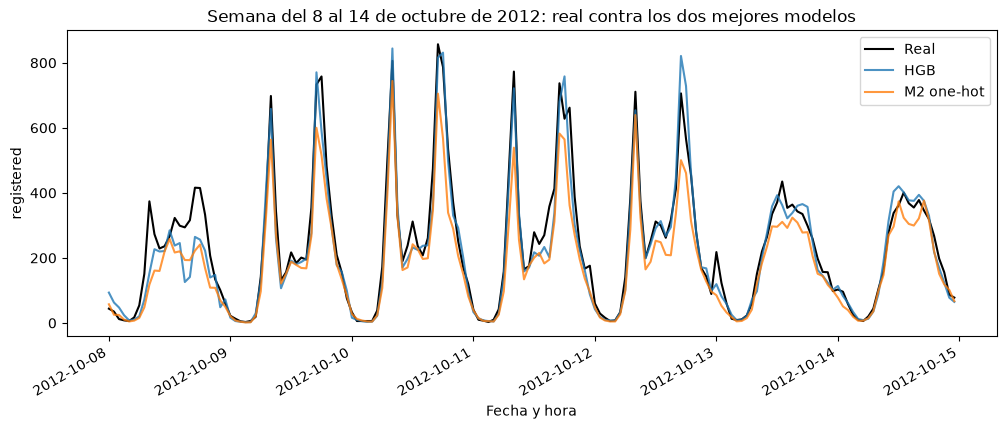

In [22]:
predicciones_finales = {
    "M4": pred_m4,
    "M4 con k_II": pred_m4_kii,
    **{n: b.predict(prueba[columnas_de[n]]) for n, b in busquedas.items()},
}
dos_mejores = tabla_final[tabla_final["modelo"] != "M4 con k_II"].nsmallest(2, "error_prueba")["modelo"].tolist()

semana = prueba[(prueba["dteday"] >= "2012-10-08") & (prueba["dteday"] <= "2012-10-14")].sort_values("momento")
idx_semana = semana.index

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(semana["momento"], semana[OBJETIVO].values, label="Real", color="black", linewidth=1.5)
for nombre in dos_mejores:
    pos = prueba.index.get_indexer(idx_semana)
    ax.plot(semana["momento"], predicciones_finales[nombre][pos], label=nombre, alpha=0.8)
ax.set_xlabel("Fecha y hora")
ax.set_ylabel(OBJETIVO)
ax.set_title("Semana del 8 al 14 de octubre de 2012: real contra los dos mejores modelos")
ax.legend()
fig.autofmt_xdate()
fig.savefig("resultados/semana_prueba.png", dpi=150)
plt.show()

**Qué significa:** en la semana del 8 al 14 de octubre de 2012, HGB y M2 (los dos modelos con menor error de prueba, sin contar M4 con `k_II`) siguen bastante bien la forma de los dos picos diarios de `registered`, aunque ambos tienden a quedarse cortos en los picos más altos (por ejemplo, el jueves 11 de octubre en la mañana, donde lo real llega a casi 850 y los modelos se quedan alrededor de 750-800). HGB sigue más de cerca los picos que M2 en varios días, consistente con tener el menor error de prueba general.


### Error por hora del día en la prueba

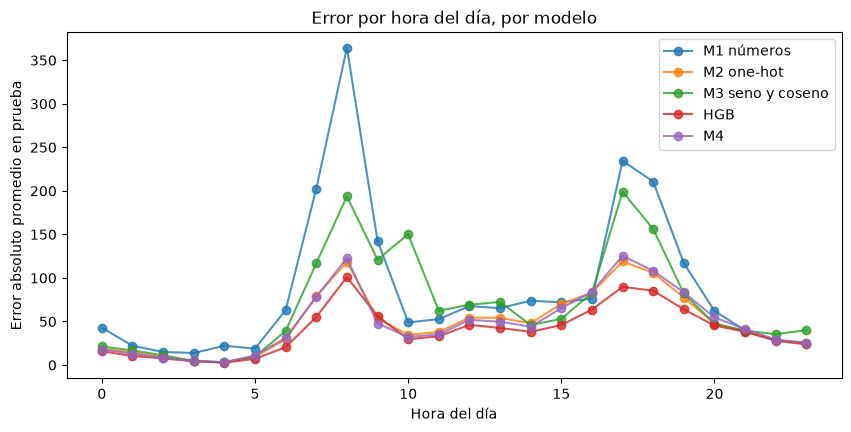

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5))
for nombre in list(busquedas.keys()) + ["M4"]:
    err_hora = pd.Series(np.abs(prueba[OBJETIVO].values - predicciones_finales[nombre]), index=prueba.index)
    perfil = err_hora.groupby(prueba["hr"]).mean().reindex(range(24))
    ax.plot(perfil.index, perfil.values, marker="o", label=nombre, alpha=0.8)
ax.set_xlabel("Hora del día")
ax.set_ylabel("Error absoluto promedio en prueba")
ax.set_title("Error por hora del día, por modelo")
ax.legend()
fig.savefig("resultados/error_por_hora.png", dpi=150)
plt.show()

**Qué significa:** el error absoluto promedio por hora confirma que todos los modelos cometen su error más grande en las horas pico (7-9 y 16-19), que es justo donde hay más bicicletas en juego, y el más chico en la madrugada (0-5), donde `registered` casi no se mueve. M1 (números) es consistentemente el peor en las horas pico, llegando a más de 360 bicicletas de error promedio a las 8am — coherente con que trata la hora como un número simple y no distingue bien horas pico de horas valle. M4 es el más parejo de los cuatro modelos de kernel en las horas pico de la tarde, pero en la mañana (7-9am) su error queda cerca del de M3 y por encima de HGB y M2, lo que es consistente con los hiperparámetros de M4 apenas explorados (celda de la malla): un `lam_h` más chico del que se probó podría ajustar mejor ese pico específico.


### ¿Valió la pena el kernel circular?

La comparación justa es **M4 contra M3**, no contra M1: por el inciso (b) de la teoría, M3 ya usa un
kernel circular válido (e^{κcos}). M4 contra M3 mide si la forma particular del kernel ayuda; M4 contra
M1 mide el beneficio de respetar que el tiempo da vuelta.

**Qué significa:** comparando M4 (48.81) contra M3 (69.86), el kernel circular combinado de M4 sí valió la pena: reduce el error de prueba en cerca de 30% frente a la codificación seno/coseno "de libro", que es la comparación que pide la teoría del inciso (e) para aislar el efecto de la forma particular del kernel (y no solo el de usar *algún* kernel circular válido). Dicho esto, M4 no logra superar a HGB, y apenas empata con M2 one-hot, así que la conclusión honesta es: construir un kernel circular a mano ayuda frente a la alternativa circular más simple (M3), pero en este problema no es suficiente para ganarle a un modelo de árboles bien afinado (HGB) ni a la codificación categórica más ingenua (M2). Esto, sumado a que los hiperparámetros de M4 quedaron en el borde de la malla sin explorar valores más pequeños, deja abierta la pregunta de si M4 podría mejorar más con una malla más amplia — queda documentado como limitación, no resuelto dentro de esta entrega.
